
# Bond Valuation and Funding Risk

This notebook evaluates the five bonds available to Kappa Foundation and develops a funding strategy for its contractual payments.

The analysis covers:

1. Bond cash flows, prices, and yields to maturity.
2. Macaulay duration, modified duration, and convexity.
3. Interest rate sensitivity using exact repricing.
4. Yield curve assumptions and changes in curve shape.
5. Bond cash-flow matching for the 2024 and 2027 payments.
6. Capital remaining for the growth portfolio.

We assumed that the bonds are fictional, default-free, and non-callable.


In [14]:

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.optimize import brentq, root, linprog
from IPython.display import display

pd.set_option("display.float_format", "{:,.4f}".format)

# Run from the project root or from its notebooks/ subfolder.
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name.lower() in {"notebooks", "notebook"} else cwd

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

for folder in [PROCESSED_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Task 2 environment ready.")

Task 2 environment ready.


In [15]:

FACE = 1000.0
INITIAL_WEALTH = 12_000_000.0
YEARS = np.arange(1, 9)

# Contractual bond information
BONDS = pd.DataFrame({
    "Bond": ["Alpha", "Beta", "Gamma", "Delta", "Epsilon"],
    "Maturity": [1, 2, 3, 5, 8],
    "Coupon Rate": [0.00, 0.00, 0.04, 0.035, 0.045],
    "Price": [958.77, 922.78, 1002.49, 986.07, 1040.71]
}).set_index("Bond")

# Mandatory payments, indexed by years after 2022
LIABILITIES = np.zeros(9)
LIABILITIES[2] = 2_400_000.0
LIABILITIES[5] = 3_600_000.0

def bond_cash_flows(maturity, coupon_rate):
    """Generate annual contractual cash flows per bond."""
    flows = np.zeros(9)
    flows[1:maturity + 1] = FACE * coupon_rate
    flows[maturity] += FACE
    return flows

CASH_FLOWS = {
    bond: bond_cash_flows(
        int(row["Maturity"]),
        row["Coupon Rate"]
    )
    for bond, row in BONDS.iterrows()
}

cash_flow_table = pd.DataFrame(
    {name: flows[1:] for name, flows in CASH_FLOWS.items()},
    index=YEARS
)

cash_flow_table.index.name = "Year from 2022"

display(BONDS)
display(cash_flow_table)


,Maturity,Coupon Rate,Price
Bond,,,
Alpha,1,0.0000,958.7700
Beta,2,0.0000,922.7800
Gamma,3,0.0400,"1,002.4900"
Delta,5,0.0350,986.0700
Epsilon,8,0.0450,"1,040.7100"


,Alpha,Beta,Gamma,Delta,Epsilon
Year from 2022,,,,,
1,"1,000.0000",0.0000,40.0000,35.0000,45.0000
2,0.0000,"1,000.0000",40.0000,35.0000,45.0000
3,0.0000,0.0000,"1,040.0000",35.0000,45.0000
4,0.0000,0.0000,0.0000,35.0000,45.0000
5,0.0000,0.0000,0.0000,"1,035.0000",45.0000
6,0.0000,0.0000,0.0000,0.0000,45.0000
7,0.0000,0.0000,0.0000,0.0000,45.0000
8,0.0000,0.0000,0.0000,0.0000,"1,045.0000"


## 1. Bond Valuation & Yield to Maturity (YTM)

A bond's clean/flat price equals the present value of its future cash flows discounted at its yield to maturity:

$$
P = \sum_{t=1}^{T} \frac{CF_t}{(1 + y)^t} = \sum_{t=1}^{T} \frac{C}{(1 + y)^t} + \frac{M}{(1 + y)^T}
$$

where:
* $P$: Current bond price.
* $CF_t$: Cash flow at period $t$ (coupon payment $C$, plus par value $M$ at maturity).
* $T$: Number of periods until maturity.
* $y$: Yield to maturity (YTM) per period.

In [3]:

def bond_price(cash_flows, ytm):
    """Calculate bond price using a single annual yield."""
    return sum(
        cash_flows[t] / (1 + ytm)**t
        for t in YEARS
    )

valuation_rows = []
YTM = {}

for name, row in BONDS.iterrows():

    flows = CASH_FLOWS[name]
    market_price = row["Price"]

    # Solve for yield to maturity
    ytm = brentq(
        lambda y: bond_price(flows, y) - market_price,
        -0.50, 1.00
    )

    YTM[name] = ytm

    # Present values of contractual cash flows
    pv = np.array([
        flows[t] / (1 + ytm)**t
        for t in YEARS
    ])

    macaulay = np.sum(YEARS * pv) / market_price
    modified = macaulay / (1 + ytm)

    convexity = sum(
        t * (t + 1) * flows[t] /
        (1 + ytm)**(t + 2)
        for t in YEARS
    ) / market_price

    valuation_rows.append({
        "Bond": name,
        "Price": market_price,
        "YTM": ytm,
        "Macaulay Duration": macaulay,
        "Modified Duration": modified,
        "Convexity": convexity
    })

valuation = pd.DataFrame(valuation_rows).set_index("Bond")

display(valuation)

valuation.to_csv(
    TABLES_DIR / "T2_bond_valuation.csv"
)


,Price,YTM,Macaulay Duration,Modified Duration,Convexity
Bond,,,,,
Alpha,958.7700,0.0430,1.0000,0.9588,1.8385
Beta,922.7800,0.0410,2.0000,1.9212,5.5367
Gamma,"1,002.4900",0.0391,2.8862,2.7776,10.5528
Delta,986.0700,0.0381,4.6704,4.4989,25.4023
Epsilon,"1,040.7100",0.0390,6.9182,6.6586,54.7855



## 2. Duration and Convexity

Bond prices move inversely with yields. 

* **Macaulay Duration ($D_{\text{mac}}$):** The weighted average maturity of future cash flows, measured in years.
* **Modified Duration ($D_{\text{mod}}$):** The percentage price change for a small change in yield:

$$
\frac{\Delta P}{P} \approx -D_{\text{mod}}\,\Delta y
$$

*Note: For annual compounding, $D_{\text{mod}} = \frac{D_{\text{mac}}}{1 + y}$.*

### Convexity Adjustment

Because duration is a linear (first-order) approximation, its accuracy drops for large shifts in yield. **Convexity ($C$)** accounts for the curvature of the price-yield curve (second-order Taylor approximation):

$$
\frac{\Delta P}{P} \approx -D_{\text{mod}}\,\Delta y + \frac{1}{2} C (\Delta y)^2
$$

The analysis below compares the linear duration estimate, the convexity-adjusted estimate, and exact bond repricing.

,Bond,Shock (bp),Exact Change,Duration Estimate,Duration + Convexity,Duration Error,Duration + Convexity Error
0,Alpha,-200,0.0196,0.0192,0.0195,-0.0004,-0.0000
1,Alpha,-100,0.0097,0.0096,0.0097,-0.0001,-0.0000
2,Alpha,100,-0.0095,-0.0096,-0.0095,-0.0001,0.0000
3,Alpha,200,-0.0188,-0.0192,-0.0188,-0.0004,0.0000
4,Beta,-200,0.0396,0.0384,0.0395,-0.0011,-0.0000
5,Beta,-100,0.0195,0.0192,0.0195,-0.0003,-0.0000
6,Beta,100,-0.0189,-0.0192,-0.0189,-0.0003,0.0000
7,Beta,200,-0.0373,-0.0384,-0.0373,-0.0011,0.0000
8,Gamma,-200,0.0577,0.0556,0.0577,-0.0022,-0.0001
9,Gamma,-100,0.0283,0.0278,0.0283,-0.0005,-0.0000


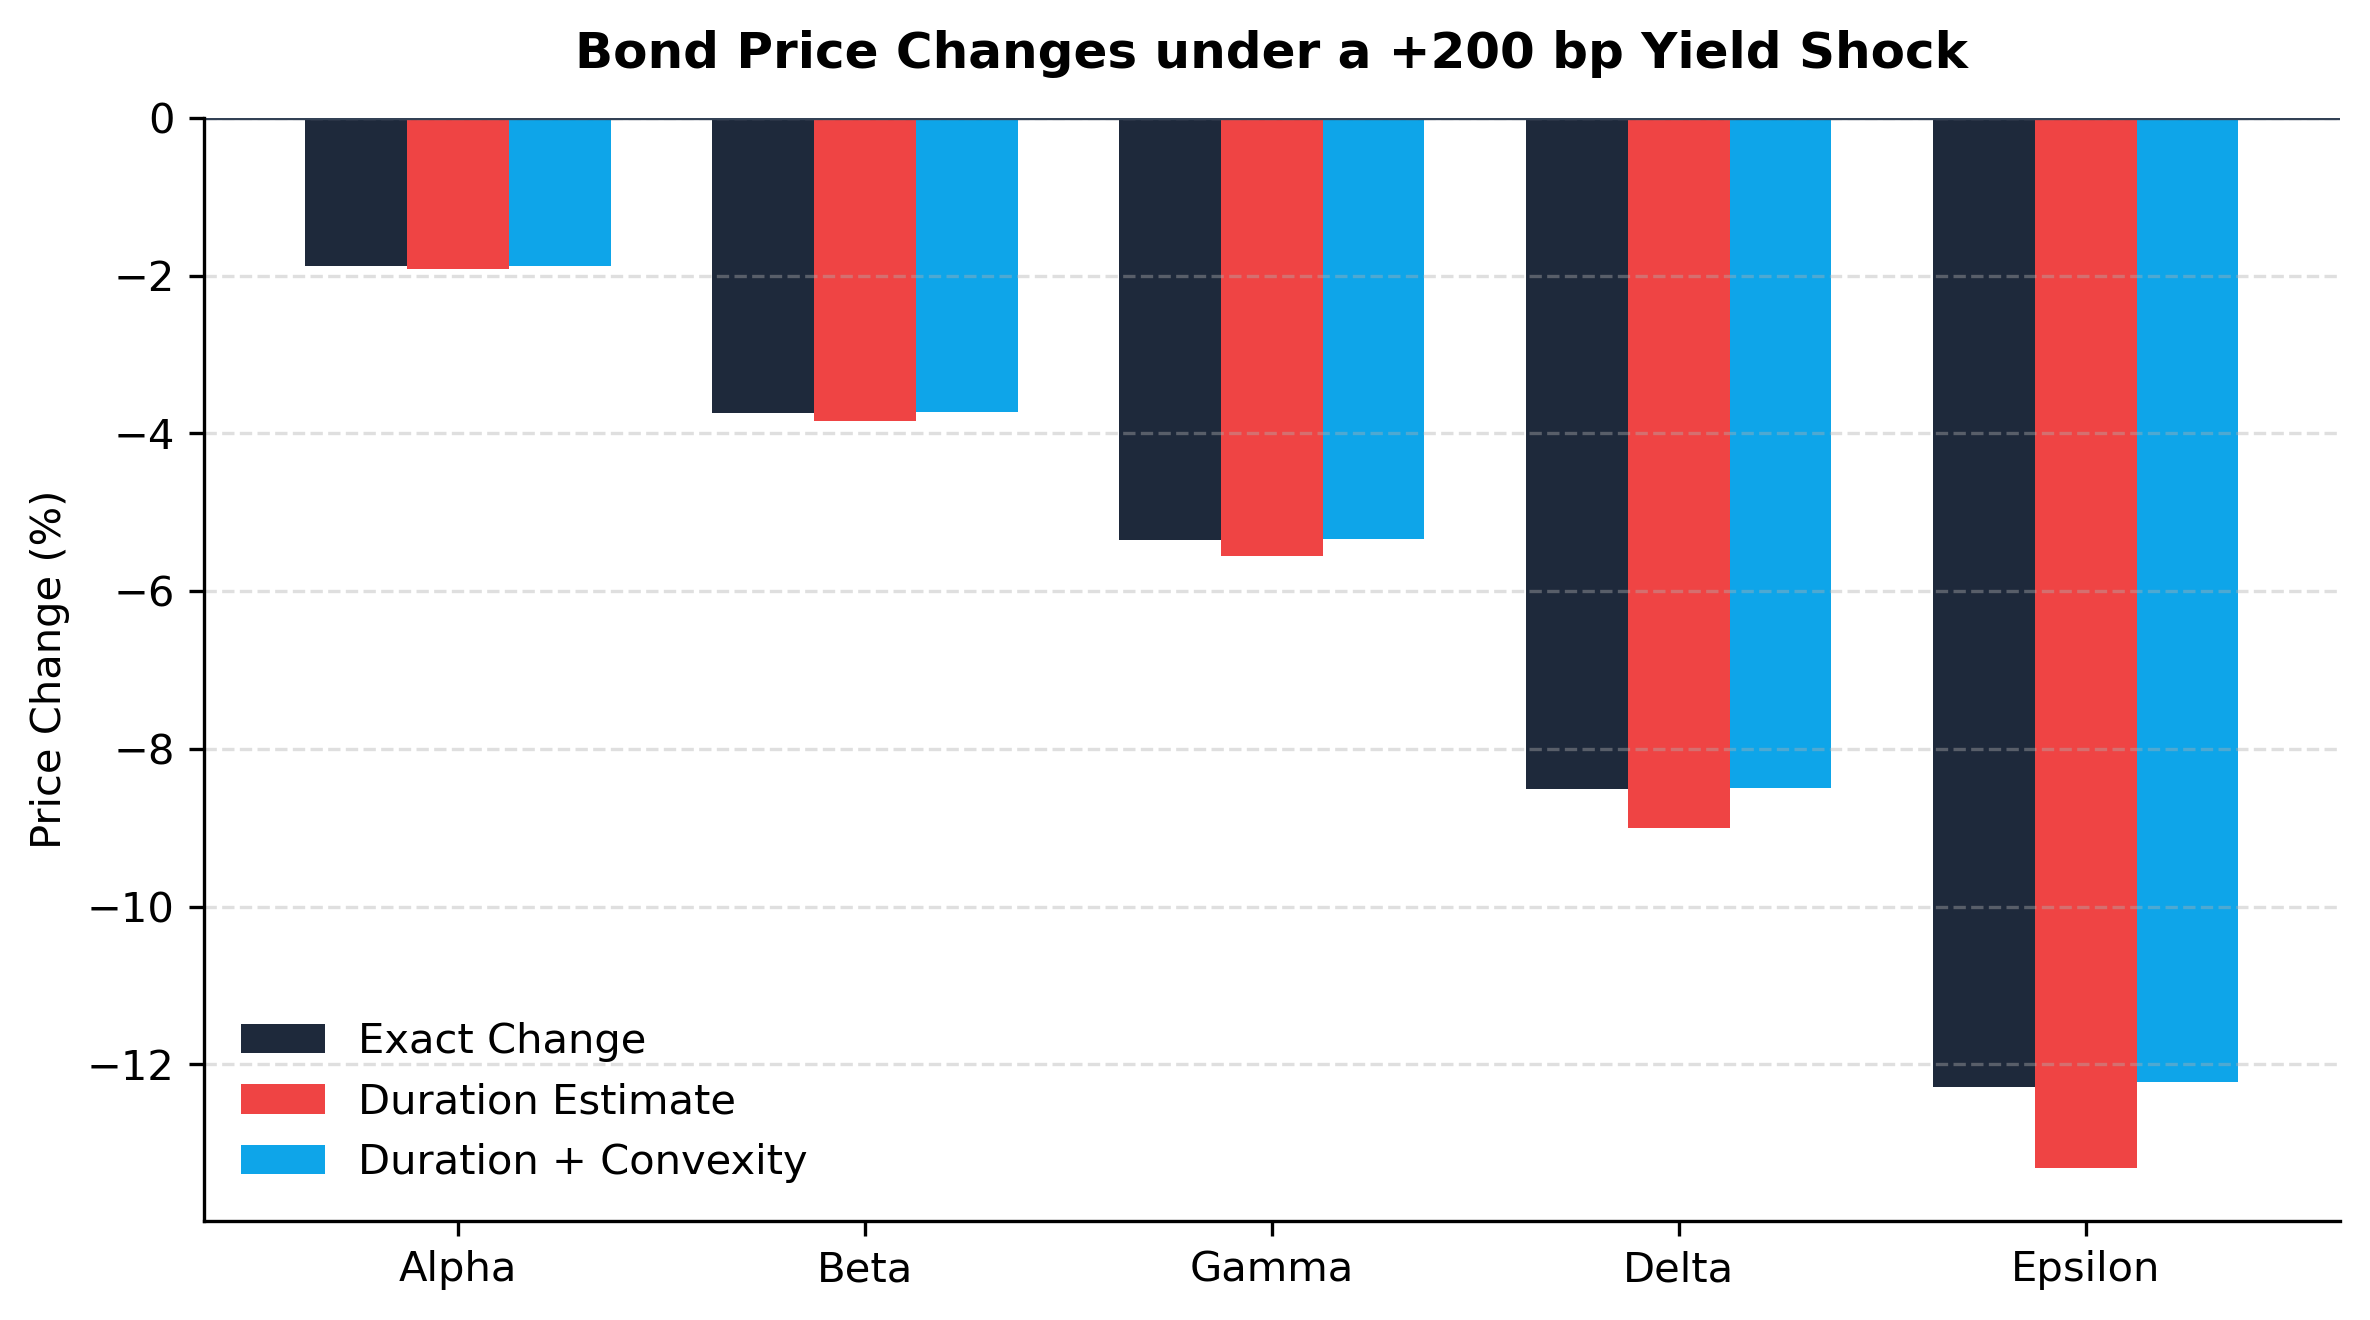

In [5]:

SHOCKS_BP = [-200, -100, 100, 200]

repricing_rows = []

for name in BONDS.index:

    price = BONDS.loc[name, "Price"]
    ytm = YTM[name]
    duration = valuation.loc[name, "Modified Duration"]
    convexity = valuation.loc[name, "Convexity"]

    for shock_bp in SHOCKS_BP:

        dy = shock_bp / 10000

        exact = (
            bond_price(CASH_FLOWS[name], ytm + dy)
            / price - 1
        )

        duration_only = -duration * dy
        duration_convexity = (
            -duration * dy + 0.5 * convexity * dy**2
        )

        repricing_rows.append({
            "Bond": name,
            "Shock (bp)": shock_bp,
            "Exact Change": exact,
            "Duration Estimate": duration_only,
            "Duration + Convexity": duration_convexity,
            "Duration Error": duration_only - exact,
            "Duration + Convexity Error":
                duration_convexity - exact
        })

repricing = pd.DataFrame(repricing_rows)

display(repricing)

repricing.to_csv(
    TABLES_DIR / "T2_exact_repricing.csv",
    index=False
)

# Compare methods for a +200 bp shock.
plot_data = repricing[repricing["Shock (bp)"] == 200].set_index("Bond")
cols = ["Exact Change", "Duration Estimate", "Duration + Convexity"]
colors = ["#1E293B", "#EF4444", "#0EA5E9"]

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)

plot_data[cols].mul(100).plot.bar(ax=ax, color=colors, width=0.75, rot=0)

ax.set_title("Bond Price Changes under a +200 bp Yield Shock", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Price Change (%)")
ax.set_xlabel("")
ax.axhline(0, color="#334155", linewidth=0.8)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "T2_duration_convexity_comparison.png", dpi=300)
plt.show()



## 3. Yield Curve and Term Structure

The case provides five bond prices but does not provide a complete zero-coupon yield curve.

The one-year and two-year spot rates can be calculated directly from Alpha and Beta. The three-year spot rate can then be derived from Gamma's price and coupon payments.

In [7]:

# Bootstrap the first three spot rates.

spot_1 = FACE / BONDS.loc["Alpha", "Price"] - 1

spot_2 = (
    FACE / BONDS.loc["Beta", "Price"]
)**0.5 - 1

spot_3 = brentq(
    lambda r:
        CASH_FLOWS["Gamma"][1] / (1 + spot_1)
        + CASH_FLOWS["Gamma"][2] / (1 + spot_2)**2
        + CASH_FLOWS["Gamma"][3] / (1 + r)**3
        - BONDS.loc["Gamma", "Price"],
    0.0, 0.20
)

def interpolate_curve(spot_5, spot_8):
    """Create annual spot rates using linear interpolation."""
    known_years = [1, 2, 3, 5, 8]
    known_rates = [spot_1, spot_2, spot_3, spot_5, spot_8]

    curve = np.zeros(9)
    curve[1:] = np.interp(
        YEARS, known_years, known_rates
    )
    return curve

def price_with_curve(flows, curve):
    """Discount each cash flow using its maturity-specific spot rate."""
    return sum(
        flows[t] / (1 + curve[t])**t
        for t in YEARS
    )

def pricing_errors(unknown):
    curve = interpolate_curve(unknown[0], unknown[1])

    return [
        price_with_curve(CASH_FLOWS["Delta"], curve)
        - BONDS.loc["Delta", "Price"],

        price_with_curve(CASH_FLOWS["Epsilon"], curve)
        - BONDS.loc["Epsilon", "Price"]
    ]

solution = root(pricing_errors, [0.04, 0.04])

if np.max(np.abs(pricing_errors(solution.x))) > 0.0001:
    raise RuntimeError("Yield curve calibration failed.")

BASE_SPOT = interpolate_curve(*solution.x)

curve_table = pd.DataFrame({
    "Year": YEARS,
    "Spot Rate": BASE_SPOT[1:]
})

display(curve_table)

curve_table.to_csv(
    TABLES_DIR / "T2_spot_curve.csv",
    index=False
)

# Verify that the curve reproduces observed bond prices.
for name in BONDS.index:

    fitted_price = price_with_curve(
        CASH_FLOWS[name], BASE_SPOT
    )

    assert np.isclose(
        fitted_price,
        BONDS.loc[name, "Price"],
        atol=0.0001
    )



,Year,Spot Rate
0,1,0.0430
1,2,0.0410
2,3,0.0390
3,4,0.0385
4,5,0.0380
5,6,0.0383
6,7,0.0387
7,8,0.0390



## 4. Interest rate scenario analysis

Two types of interest rate changes are considered.

- A **parallel shift** increases or decreases spot rates across all maturities by the same amount.
- A **nonparallel shift** changes short-term and long-term rates by different amounts, altering the shape of the yield curve.

The analysis uses 100 and 200 basis point parallel shifts, together with two nonparallel scenarios involving different changes at the one-year and eight-year maturities.


In [8]:
# Each scenario specifies the shock at years 1 and 8.
RATE_SCENARIOS = {
    "Parallel +100 bp": (100, 100),
    "Parallel -100 bp": (-100, -100),
    "Parallel +200 bp": (200, 200),
    "Parallel -200 bp": (-200, -200),
    "Short rates rise": (100, 0),
    "Short up, long down": (100, -100)
}

def shocked_curve(base_curve, short_bp, long_bp):
    """Apply an interpolated spot-rate shock."""
    shock = np.zeros(9)
    shock[1:] = np.linspace(
        short_bp, long_bp, 8
    ) / 10000

    return base_curve + shock

scenario_rows = []

for scenario, (short_bp, long_bp) in RATE_SCENARIOS.items():

    curve = shocked_curve(
        BASE_SPOT, short_bp, long_bp
    )

    for name in BONDS.index:

        shocked_price = price_with_curve(
            CASH_FLOWS[name], curve
        )

        initial_price = BONDS.loc[name, "Price"]

        scenario_rows.append({
            "Scenario": scenario,
            "Bond": name,
            "New Price": shocked_price,
            "Price Change":
                shocked_price / initial_price - 1
        })

scenario_results = pd.DataFrame(scenario_rows)

display(
    scenario_results.pivot(
        index="Bond",
        columns="Scenario",
        values="Price Change"
    )
)

scenario_results.to_csv(
    TABLES_DIR / "T2_rate_scenarios.csv",
    index=False
)

Scenario,Parallel +100 bp,Parallel +200 bp,Parallel -100 bp,Parallel -200 bp,Short rates rise,"Short up, long down"
Bond,,,,,,
Alpha,-0.0095,-0.0188,0.0097,0.0196,-0.0095,-0.0095
Beta,-0.0189,-0.0373,0.0195,0.0396,-0.0163,-0.0136
Delta,-0.0438,-0.0851,0.0463,0.0953,-0.0199,0.0047
Epsilon,-0.0639,-0.1229,0.0694,0.1449,-0.0042,0.0606
Gamma,-0.0273,-0.0535,0.0283,0.0577,-0.0198,-0.0122



## 5. Liability Funding and Cash Flow Matching

We use an approach that holding Beta, which matures in 2024, and Delta, which matures in 2027.

Coupon payments received before they are needed can be retained as cash. For a conservative funding test, the cash balance is assumed to earn 0% interest.

We compare two funding approaches:

- **Simple maturity matching:** Use Beta's principal for the 2024 payment and Delta's final principal and coupon for the 2027 payment, without relying on earlier coupons.
- **Minimum-cost cash-flow matching:** Choose nonnegative holdings of the five available bonds to minimize the initial cost while ensuring that cumulative contractual cash flows cover every scheduled payment, assuming no return on retained cash.

In [ ]:

BOND_NAMES = BONDS.index.tolist()

prices = BONDS.loc[BOND_NAMES, "Price"].to_numpy()

# A. Simple maturity matching using Beta and Delta.
simple_units = np.zeros(len(BOND_NAMES))

beta_index = BOND_NAMES.index("Beta")
delta_index = BOND_NAMES.index("Delta")

simple_units[beta_index] = (
    LIABILITIES[2] / FACE
)

delta_final_payment = (
    CASH_FLOWS["Delta"][5]
)

simple_units[delta_index] = (
    LIABILITIES[5] / delta_final_payment
)

# B. Minimum-cost cash-flow matching.

bond_matrix = np.column_stack([
    CASH_FLOWS[name][1:6]
    for name in BOND_NAMES
])

cumulative_flows = np.cumsum(bond_matrix, axis=0)
cumulative_payments = np.cumsum(LIABILITIES[1:6])

optimization = linprog(
    c=prices,
    A_ub=-cumulative_flows,
    b_ub=-cumulative_payments,
    bounds=(0, None),
    method="highs"
)

if not optimization.success:
    raise RuntimeError(optimization.message)

optimal_units = optimization.x

STRATEGIES = {
    "Simple maturity matching": simple_units,
    "Minimum-cost matching": optimal_units
}

funding_rows = []

for name, units in STRATEGIES.items():

    funding_cost = float(units @ prices)

    funding_rows.append({
        "Strategy": name,
        "Funding Cost USD": funding_cost,
        "Percentage of Fund": funding_cost / INITIAL_WEALTH,
        "Remaining Growth Capital USD":
            INITIAL_WEALTH - funding_cost
    })

funding_table = pd.DataFrame(funding_rows)

display(funding_table)

funding_table.to_csv(
    TABLES_DIR / "T2_funding_comparison.csv",
    index=False
)

holdings_table = pd.DataFrame(
    STRATEGIES,
    index=BOND_NAMES
)

holdings_table.index.name = "Bond"

display(holdings_table)

holdings_table.to_csv(
    TABLES_DIR / "T2_funding_holdings.csv"
)


,Strategy,Funding Cost USD,Percentage of Fund,Remaining Growth Capital USD
0,Simple maturity matching,"5,644,480.6957",0.4704,"6,355,519.3043"
1,Minimum-cost matching,"5,216,763.8009",0.4347,"6,783,236.1991"


,Simple maturity matching,Minimum-cost matching
Bond,,
Alpha,0.0000,0.0000
Beta,"2,400.0000","2,171.9457"
Gamma,0.0000,0.0000
Delta,"3,478.2609","3,257.9186"
Epsilon,0.0000,0.0000


In [ ]:
# Use the minimum-cost strategy as the funding candidate.
RECOMMENDED_UNITS = optimal_units.copy()

portfolio_flows = sum(
    RECOMMENDED_UNITS[i] * CASH_FLOWS[name]
    for i, name in enumerate(BOND_NAMES)
)

cash_rows = []
cash_balance = 0.0

for t in range(1, 6):

    beginning_cash = cash_balance
    bond_inflow = portfolio_flows[t]
    payment = LIABILITIES[t]

    cash_balance = (
        beginning_cash + bond_inflow - payment
    )

    if cash_balance < -0.01:
        raise ValueError(
            f"Funding shortfall in year {2022 + t}."
        )

    cash_rows.append({
        "Year": 2022 + t,
        "Beginning Cash": beginning_cash,
        "Bond Cash Flow": bond_inflow,
        "Liability Payment": payment,
        "Ending Cash": cash_balance
    })

funding_cash_table = pd.DataFrame(cash_rows)

display(funding_cash_table)

funding_cash_table.to_csv(
    TABLES_DIR / "T2_funding_cash_flows.csv",
    index=False
)

FUNDING_COST = float(RECOMMENDED_UNITS @ prices)

GROWTH_CAPITAL = INITIAL_WEALTH - FUNDING_COST

assert GROWTH_CAPITAL >= 0

print(f"Initial funding allocation: ${FUNDING_COST:,.2f}")
print(f"Remaining growth capital: ${GROWTH_CAPITAL:,.2f}")
print("All mandatory payments are funded.")

,Year,Beginning Cash,Bond Cash Flow,Liability Payment,Ending Cash
0,2023,0.0000,"114,027.1493",0.0000,"114,027.1493"
1,2024,"114,027.1493","2,285,972.8507","2,400,000.0000",0.0000
2,2025,0.0000,"114,027.1493",0.0000,"114,027.1493"
3,2026,"114,027.1493","114,027.1493",0.0000,"228,054.2986"
4,2027,"228,054.2986","3,371,945.7014","3,600,000.0000",-0.0000


Initial funding allocation: $5,216,763.80
Remaining growth capital: $6,783,236.20
All mandatory payments are funded.


In [16]:
# Compare the present values of the funding assets and liabilities
funding_asset_flows = portfolio_flows

stress_rows = []

for scenario, (short_bp, long_bp) in RATE_SCENARIOS.items():

    stressed_curve = shocked_curve(
        BASE_SPOT, short_bp, long_bp
    )

    asset_pv = price_with_curve(
        funding_asset_flows, stressed_curve
    )

    liability_pv = price_with_curve(
        LIABILITIES, stressed_curve
    )

    stress_rows.append({
        "Scenario": scenario,
        "Asset PV USD": asset_pv,
        "Liability PV USD": liability_pv,
        "PV Surplus USD": asset_pv - liability_pv
    })

funding_stress = pd.DataFrame(stress_rows)

display(funding_stress[["Scenario", "PV Surplus USD"]])

funding_stress.to_csv(
    TABLES_DIR / "T2_funding_rate_stress.csv",
    index=False
)


import json

# Save the funding decision and available growth capital.
task2_results = {
    "initial_wealth_usd": INITIAL_WEALTH,
    "funding_strategy": "Minimum-cost matching",
    "funding_cost_usd": FUNDING_COST,
    "growth_capital_usd": GROWTH_CAPITAL,
    "funding_percentage": FUNDING_COST / INITIAL_WEALTH,
    "bond_units": {
        name: float(RECOMMENDED_UNITS[i])
        for i, name in enumerate(BOND_NAMES)
    },
    "cash_reinvestment_rate": 0.0,
    "bond_trading_cost_assumption": 0.0,
    "funding_cash_flows_verified": True
}

RESULTS_FILE = PROCESSED_DIR / "task2_funding_results.json"

with RESULTS_FILE.open("w", encoding="utf-8") as file:
    json.dump(task2_results, file, indent=4)

# Final validation
assert FUNDING_COST <= INITIAL_WEALTH
assert funding_cash_table["Ending Cash"].min() >= -0.01
assert np.isclose(
    FUNDING_COST + GROWTH_CAPITAL,
    INITIAL_WEALTH
)

print("=" * 50)
print("TASK 2 — BOND AND FUNDING ANALYSIS COMPLETE")
print("=" * 50)
print(f"Liability funding: ${FUNDING_COST:,.2f}")
print(f"Growth capital: ${GROWTH_CAPITAL:,.2f}")
print("Mandatory payments: Covered")


,Scenario,PV Surplus USD
0,Parallel +100 bp,"17,791.9383"
1,Parallel -100 bp,"11,028.1795"
2,Parallel +200 bp,"20,788.5264"
3,Parallel -200 bp,"7,218.4152"
4,Short rates rise,"14,881.1609"
5,"Short up, long down","11,843.2605"


TASK 2 — BOND AND FUNDING ANALYSIS COMPLETE
Liability funding: $5,216,763.80
Growth capital: $6,783,236.20
Mandatory payments: Covered



## 6. Interpretation

Longer-duration bonds are generally more sensitive to interest rate changes. Convexity improves the accuracy of duration-based price estimates, especially under larger yield shifts.

For Kappa Foundation, the priority is meeting contractual payments rather than maximizing bond returns. The cash-flow matching strategy supports both liabilities without relying on future bond sales or positive reinvestment returns.

Although interest rate changes affect bond market values, the promised cash flows remain unchanged if the bonds are held to maturity.

The remaining capital is available for growth investment, subject to the foundation's risk tolerance and 2030 purchasing-power objective.


In [ ]:

import json
# Save the funding decision and available growth capital.
task2_results = {
    "initial_wealth_usd": INITIAL_WEALTH,
    "funding_strategy": "Minimum-cost matching",
    "funding_cost_usd": FUNDING_COST,
    "growth_capital_usd": GROWTH_CAPITAL,
    "funding_percentage": FUNDING_COST / INITIAL_WEALTH,
    "bond_units": {
        name: float(RECOMMENDED_UNITS[i])
        for i, name in enumerate(BOND_NAMES)
    },
    "cash_reinvestment_rate": 0.0,
    "bond_trading_cost_assumption": 0.0,
    "funding_cash_flows_verified": True
}

RESULTS_FILE = PROCESSED_DIR / "task2_funding_results.json"

with RESULTS_FILE.open("w", encoding="utf-8") as file:
    json.dump(task2_results, file, indent=4)

# Final validation
assert FUNDING_COST <= INITIAL_WEALTH
assert funding_cash_table["Ending Cash"].min() >= -0.01
assert np.isclose(
    FUNDING_COST + GROWTH_CAPITAL,
    INITIAL_WEALTH
)

print("=" * 50)
print("TASK 2 — BOND AND FUNDING ANALYSIS COMPLETE")
print("=" * 50)
print(f"Liability funding: ${FUNDING_COST:,.2f}")
print(f"Growth capital: ${GROWTH_CAPITAL:,.2f}")
print("Mandatory payments: Covered")


TASK 2 — BOND AND FUNDING ANALYSIS COMPLETE
Liability funding: $5,216,763.80
Growth capital: $6,783,236.20
Mandatory payments: Covered
Results exported successfully.
